# MI3031 – Suy luận thống kê | Nhóm 4
## Ước lượng khoảng tin cậy 95% cho kết quả học tập

**Bộ dữ liệu:** *Students Performance in Exams* (Kaggle) – 1.000 học sinh, 8 biến.

**Nội dung:**

| Câu | Yêu cầu | Biến sử dụng | Phương pháp |
|---|---|---|---|
| a | KTC 95% cho kỳ vọng $\mu$ | `math score` | $z$ – mẫu lớn (định lý giới hạn trung tâm) |
| b | KTC 95% cho phương sai $\sigma^2$ | `math score` | $\chi^2$ (cần tổng thể chuẩn) |
| c | KTC 95% cho tỷ lệ $p$ | `test preparation course` (`completed`) | $z$ – xấp xỉ chuẩn (CLT) |
| d | KTC 95% cho hiệu kỳ vọng $\mu_1-\mu_2$ | `math score` theo nhóm `test preparation course` | $z$ – mẫu lớn (CLT) |

**Nguyên tắc trình bày:** mỗi câu gồm (1) công thức, (2) điều kiện áp dụng, (3) code tính toán *từng bước bằng công thức* (không dùng sẵn `mean()`, `std()`, ...), (4) diễn giải theo ngữ cảnh dữ liệu. Thư viện `scipy` chỉ dùng để tra **phân vị** (chuẩn tắc, $\chi^2$, $t$ đối chiếu) vì không có công thức đóng đơn giản, còn lại đều tính tay.

## Cơ sở lý thuyết 

$z_{\alpha/2}$ là giá trị tới hạn bên phải, $P(Z>z_{\alpha/2})=\alpha/2$ (với 95%: $z_{0{,}025}=1{,}96$); tương tự $\chi^2_{\alpha/2,\,n-1}$.

- **Định lý giới hạn trung tâm**: nếu mẫu $(X_1,\dots,X_n)$ từ biến gốc $X$ có phân phối *bất kỳ* với $E(X)=\mu$, $V(X)=\sigma^2$ hữu hạn thì
$$Z=\frac{\bar X-\mu}{\sigma/\sqrt n}\ \approx\ N(0,1)\quad(n\to\infty).$$
  Xấp xỉ chuẩn tốt khi $n\ge30$ nếu tổng thể không quá xa phân phối chuẩn.
- **Hiệu hai trung bình mẫu**: hai mẫu độc lập, $n_1,n_2\ge30$ ⇒ $\bar X_1-\bar X_2$ xấp xỉ chuẩn với kỳ vọng $\mu_1-\mu_2$, phương sai $\sigma_1^2/n_1+\sigma_2^2/n_2$.
- **Tỷ lệ mẫu**: $\hat P=Y/n$ là trung bình của các biến Bernoulli ⇒ xấp xỉ chuẩn nếu $np\ge5$ và $n(1-p)\ge5$.
- **Mẫu lớn, $\sigma$ chưa biết**: thay $\sigma$ bằng độ lệch chuẩn mẫu hiệu chỉnh $S$ mà $Z$ vẫn tiệm cận $N(0,1)$; khuyến nghị $n\ge40$.
- **Phương sai**: khoảng $\chi^2$ cho $\sigma^2$ **yêu cầu tổng thể chuẩn**; định lý giới hạn trung tâm *không* áp dụng cho khoảng này, nên câu b vẫn phải kiểm tra giả định chuẩn.

→ Vì $n=1000$ (và hai nhóm ở câu d đều lớn), các câu **a, c, d** dùng xấp xỉ chuẩn (phân vị $z_{\alpha/2}$) dựa trên định lý giới hạn trung tâm; câu **b** dùng $\chi^2$ với điều kiện chuẩn.

---
# Phần 1–2. Giới thiệu bộ dữ liệu

### (a) Bối cảnh và ý nghĩa
Bộ dữ liệu ghi nhận **điểm thi ba môn (Toán, Đọc hiểu, Viết)** của 1.000 học sinh cùng một số đặc điểm nền: giới tính, nhóm chủng tộc/dân tộc, trình độ học vấn của cha mẹ, loại bữa trưa (chuẩn/giảm giá – phản ánh điều kiện kinh tế) và việc học sinh **có hoàn thành khóa ôn tập** trước kỳ thi hay không. Dữ liệu cho phép trả lời các câu hỏi như: điểm Toán trung bình của học sinh là bao nhiêu, mức độ phân tán ra sao, bao nhiêu phần trăm học sinh hoàn thành khóa ôn tập, và khóa ôn tập có đi kèm điểm cao hơn hay không.

### (b) Phân loại biến
| Biến | Loại | Ghi chú |
|---|---|---|
| `gender` | Định tính (nhị phân) | female / male |
| `race/ethnicity` | Định tính (danh nghĩa) | group A – E |
| `parental level of education` | Định tính (thứ bậc) | some high school … master's degree |
| `lunch` | Định tính (nhị phân) | standard / free/reduced |
| `test preparation course` | Định tính (nhị phân) | completed / none |
| `math score` | Định lượng (liên tục, 0–100) | |
| `reading score` | Định lượng (liên tục, 0–100) | |
| `writing score` | Định lượng (liên tục, 0–100) | |

Bộ dữ liệu có $n=1000\ge 50$ quan sát, 3 biến định lượng và 5 biến định tính → **đáp ứng yêu cầu đề bài**.

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t as t_dist, chi2, normaltest

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "grid.alpha": 0.3})

# ---- Đọc dữ liệu: đặt StudentsPerformance.csv cạnh notebook hoặc sửa đường dẫn dưới đây
DATA_PATH = Path("StudentsPerformance.csv")
if not DATA_PATH.is_file():
    try:                                    # phương án dự phòng: tải bằng kagglehub
        import kagglehub
        DATA_PATH = Path(kagglehub.dataset_download(
            "spscientist/students-performance-in-exams")) / "StudentsPerformance.csv"
    except Exception as e:
        raise FileNotFoundError(
            f"Không tìm thấy {DATA_PATH}. Hãy tải từ Kaggle và đặt cạnh notebook.") from e

df = pd.read_csv(DATA_PATH)
display(df.head())

print("Kích thước:", df.shape)
print("\nGiá trị thiếu theo cột:\n", df.isna().sum().to_string())
print("\nSố dòng trùng lặp:", df.duplicated().sum())
score_cols = ["math score", "reading score", "writing score"]
print("\nMiền giá trị điểm:")
display(df[score_cols].agg(["min", "max"]).T)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Kích thước: (1000, 8)

Giá trị thiếu theo cột:
 gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0

Số dòng trùng lặp: 0

Miền giá trị điểm:


,min,max
math score,0,100
reading score,17,100
writing score,10,100


In [11]:
# Thống kê mô tả (tính tay bằng công thức)
rows = []
for col in score_cols:
    v = df[col].to_numpy(dtype=float)
    n_ = len(v); m_ = v.sum() / n_
    s2_ = ((v - m_) ** 2).sum() / (n_ - 1)
    rows.append([col, n_, m_, np.sqrt(s2_), s2_, v.min(), v.max()])
display(pd.DataFrame(rows, columns=["Biến", "n", "Trung bình", "Độ lệch chuẩn", "Phương sai", "Min", "Max"]))

print("Tần số biến test preparation course:")
display(df["test preparation course"].value_counts().to_frame("Tần số"))

,Biến,n,Trung bình,Độ lệch chuẩn,Phương sai,Min,Max
0,math score,1000,66.0890,15.1631,229.9190,0.0000,100.0000
1,reading score,1000,69.1690,14.6002,213.1656,17.0000,100.0000
2,writing score,1000,68.0540,15.1957,230.9080,10.0000,100.0000


Tần số biến test preparation course:


,Tần số
test preparation course,
none,642
completed,358


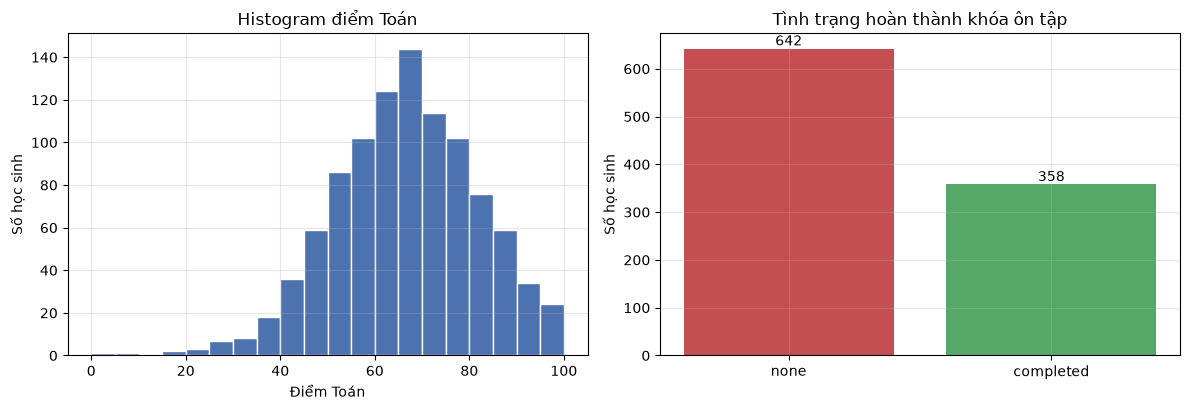

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].hist(df["math score"], bins=20, edgecolor="white", color="#4C72B0")
axes[0].set_title("Histogram điểm Toán"); axes[0].set_xlabel("Điểm Toán"); axes[0].set_ylabel("Số học sinh")

cnt = df["test preparation course"].value_counts()
bars = axes[1].bar(cnt.index, cnt.values, color=["#C44E52", "#55A868"][:len(cnt)])
axes[1].bar_label(bars)
axes[1].set_title("Tình trạng hoàn thành khóa ôn tập"); axes[1].set_ylabel("Số học sinh")
plt.tight_layout(); plt.show()

---
# Câu a. KTC 95% cho kỳ vọng tổng thể – điểm Toán (mẫu lớn)

**Bước 1. Biến và tham số.** $X=\text{math score}$ (điểm Toán của một học sinh). Tham số cần ước lượng: $\mu=E(X)$.

**Bước 2. Đặc trưng mẫu và ước lượng điểm.** Với mẫu $x_1,\dots,x_n$:

$$\bar x=\frac1n\sum_{i=1}^n x_i,\qquad s^2=\frac{\sum_{i=1}^n (x_i-\bar x)^2}{n-1},\qquad s=\sqrt{s^2},\qquad \hat\mu=\bar x .$$

**Bước 3. Cơ sở và điều kiện áp dụng.**
- Mẫu ngẫu nhiên, các quan sát độc lập; $X$ có phân phối bất kỳ (không bắt buộc chuẩn), $\mu,\sigma^2$ hữu hạn, $\sigma^2$ chưa biết.
- Cỡ mẫu **lớn**: $n\ge30$ để xấp xỉ chuẩn theo định lý giới hạn trung tâm; khuyến nghị $n\ge40$ để bù sai số do thay $\sigma$ bằng $s$.
- Khi đó $Z=\dfrac{\bar X-\mu}{S/\sqrt n}\approx N(0,1)$.

**Bước 4. Phân vị.** $z_{\alpha/2}$ với $\alpha=0{,}05$: $z_{0{,}025}=1{,}96$.

**Bước 5. Khoảng tin cậy đối xứng.**
$$\bar x-z_{\alpha/2}\frac{s}{\sqrt n}\ <\ \mu\ <\ \bar x+z_{\alpha/2}\frac{s}{\sqrt n}\qquad(\text{KTC}=\text{ước lượng điểm}\pm\text{sai số}).$$

**Bước 6. Diễn giải** theo ngữ cảnh: khoảng này ước lượng *điểm Toán trung bình của tổng thể học sinh*, **không** phải khoảng chứa điểm của từng học sinh.

In [13]:
# ---- Bước 1-2: đặc trưng mẫu (tính trực tiếp bằng công thức)
x = pd.to_numeric(df["math score"], errors="raise").to_numpy(dtype=float)
assert np.isfinite(x).all(), "Dữ liệu có giá trị thiếu/không hợp lệ."

n_a = len(x)
sum_x = x.sum()
xbar = sum_x / n_a
ss_a = ((x - xbar) ** 2).sum()
s2_a = ss_a / (n_a - 1)
s_a = np.sqrt(s2_a)

# ---- Bước 3: kiểm tra điều kiện mẫu lớn
print("Điều kiện mẫu lớn: n >= 30 (CLT):", n_a >= 30, "| khuyến nghị n >= 40:", n_a >= 40)

# ---- Bước 4-5: khoảng tin cậy dùng phân vị chuẩn tắc
alpha = 0.05
z_crit = norm.ppf(1 - alpha / 2)                 # z_{α/2}
se_a = s_a / np.sqrt(n_a)
margin_a = z_crit * se_a
lower_a, upper_a = xbar - margin_a, xbar + margin_a

# Đối chiếu (không dùng cho kết luận): nếu dùng phân vị t_{α/2, n-1}
t_crit = t_dist.ppf(1 - alpha / 2, n_a - 1)

print("\nCÂU A – KTC 95% CHO KỲ VỌNG ĐIỂM TOÁN (MẪU LỚN)")
print(f"Bước 2: n = {n_a};  Σx_i = {sum_x:.4f}")
print(f"  x̄  = {sum_x:.4f} / {n_a} = {xbar:.4f}")
print(f"  Σ(x_i - x̄)² = {ss_a:.4f}")
print(f"  s² = {ss_a:.4f} / ({n_a} - 1) = {s2_a:.4f};   s = √{s2_a:.4f} = {s_a:.4f}")
print(f"Bước 4: α = {alpha};  z_(α/2) = z_0.025 = {z_crit:.4f}")
print(f"  SE = s/√n = {s_a:.4f}/√{n_a} = {se_a:.4f}")
print(f"  Sai số biên E = {z_crit:.4f} × {se_a:.4f} = {margin_a:.4f}")
print(f"Bước 5: KTC(μ) = {xbar:.4f} ± {margin_a:.4f} = ({lower_a:.4f}; {upper_a:.4f})")
print(f"\n[Đối chiếu] t_(0.025; {n_a-1}) = {t_crit:.4f} ≈ z_0.025 = {z_crit:.4f} → khoảng gần như không đổi.")

Điều kiện mẫu lớn: n >= 30 (CLT): True | khuyến nghị n >= 40: True

CÂU A – KTC 95% CHO KỲ VỌNG ĐIỂM TOÁN (MẪU LỚN)
Bước 2: n = 1000;  Σx_i = 66089.0000
  x̄  = 66089.0000 / 1000 = 66.0890
  Σ(x_i - x̄)² = 229689.0790
  s² = 229689.0790 / (1000 - 1) = 229.9190;   s = √229.9190 = 15.1631
Bước 4: α = 0.05;  z_(α/2) = z_0.025 = 1.9600
  SE = s/√n = 15.1631/√1000 = 0.4795
  Sai số biên E = 1.9600 × 0.4795 = 0.9398
Bước 5: KTC(μ) = 66.0890 ± 0.9398 = (65.1492; 67.0288)

[Đối chiếu] t_(0.025; 999) = 1.9623 ≈ z_0.025 = 1.9600 → khoảng gần như không đổi.


In [14]:
from IPython.display import Markdown
display(Markdown(f'''
**Diễn giải (câu a).** Với mức tin cậy 95%, điểm Toán trung bình của tổng thể học sinh nằm trong khoảng
**({lower_a:.2f}; {upper_a:.2f}) điểm** (ước lượng điểm x̄ = {xbar:.2f}, sai số ≈ {margin_a:.2f} điểm).
Nghĩa là: nếu lặp lại việc lấy mẫu nhiều lần và mỗi lần dựng khoảng bằng cùng công thức, khoảng 95% số khoảng sẽ chứa μ thật.
Khoảng này **không** nói rằng 95% học sinh có điểm Toán trong đoạn đó.
Do n = {n_a} ≥ 40 nên xấp xỉ chuẩn theo định lý giới hạn trung tâm là hợp lý, kể cả khi điểm Toán không chuẩn hoàn toàn.
'''))


**Diễn giải (câu a).** Với mức tin cậy 95%, điểm Toán trung bình của tổng thể học sinh nằm trong khoảng
**(65.15; 67.03) điểm** (ước lượng điểm x̄ = 66.09, sai số ≈ 0.94 điểm).
Nghĩa là: nếu lặp lại việc lấy mẫu nhiều lần và mỗi lần dựng khoảng bằng cùng công thức, khoảng 95% số khoảng sẽ chứa μ thật.
Khoảng này **không** nói rằng 95% học sinh có điểm Toán trong đoạn đó.
Do n = 1000 ≥ 40 nên xấp xỉ chuẩn theo định lý giới hạn trung tâm là hợp lý, kể cả khi điểm Toán không chuẩn hoàn toàn.


---
# Câu b. KTC 95% cho phương sai tổng thể – điểm Toán

**Bước 1. Biến và tham số.** $X=\text{math score}$; tham số cần ước lượng $\sigma^2=\operatorname{Var}(X)$ (đơn vị: điểm²).

**Bước 2. Ước lượng điểm.** $\hat\sigma^2=s^2=\dfrac{\sum (x_i-\bar x)^2}{n-1}$.

**Bước 3. Điều kiện áp dụng.** Mẫu ngẫu nhiên từ tổng thể **có phân phối chuẩn** $N(\mu,\sigma^2)$, cả $\mu,\sigma^2$ chưa biết. Khi đó
$$K^2=\frac{(n-1)S^2}{\sigma^2}\sim\chi^2(n-1).$$

> ⚠️ **Khác với câu a, c, d:** định lý giới hạn trung tâm chỉ nói về *trung bình* (và tỷ lệ), **không** làm cho thống kê $K^2$ có phân phối $\chi^2$ khi tổng thể không chuẩn. Vì vậy dù $n$ lớn vẫn phải **kiểm tra giả định chuẩn** trước khi dùng khoảng $\chi^2$.

**Bước 4. Phân vị.** Bậc tự do $\nu=n-1$. Theo ký hiệu slide, $\chi^2_{\alpha/2,\,\nu}$ là giá trị tới hạn *bên phải* (xác suất bên phải bằng $\alpha/2$) và $\chi^2_{1-\alpha/2,\,\nu}$ là giá trị tới hạn có xác suất bên phải bằng $1-\alpha/2$ (tức là phân vị mức $\alpha/2$ từ bên trái).

**Bước 5. Khoảng tin cậy.** Từ $P\!\left(\chi^2_{1-\alpha/2,\nu}<K^2<\chi^2_{\alpha/2,\nu}\right)=1-\alpha$ suy ra
$$\frac{(n-1)s^2}{\chi^2_{\alpha/2,\,n-1}}\ <\ \sigma^2\ <\ \frac{(n-1)s^2}{\chi^2_{1-\alpha/2,\,n-1}},$$
lấy căn hai cận ta được khoảng tin cậy cho độ lệch chuẩn $\sigma$.

In [15]:
# ---- Bước 2-5: khoảng chi-square (ký hiệu theo slide: giá trị tới hạn bên phải)
dof_b = n_a - 1
chi2_a2  = chi2.isf(alpha / 2, dof_b)        # χ²_{α/2, ν}   (xác suất bên phải = α/2)
chi2_1a2 = chi2.isf(1 - alpha / 2, dof_b)    # χ²_{1-α/2, ν} (xác suất bên phải = 1-α/2)
num_b = dof_b * s2_a
lower_b = num_b / chi2_a2
upper_b = num_b / chi2_1a2

print("\nCÂU B – KTC 95% CHO PHƯƠNG SAI ĐIỂM TOÁN")
print(f"Bước 2: s² = {ss_a:.4f} / ({n_a} - 1) = {s2_a:.4f} điểm²")
print(f"Bước 4: ν = {dof_b};  χ²_(0.025; {dof_b}) = {chi2_a2:.4f};  χ²_(0.975; {dof_b}) = {chi2_1a2:.4f}")
print(f"Bước 5: (n-1)s² = {dof_b} × {s2_a:.4f} = {num_b:.4f}")
print(f"  Cận dưới = {num_b:.4f} / {chi2_a2:.4f} = {lower_b:.4f}")
print(f"  Cận trên = {num_b:.4f} / {chi2_1a2:.4f} = {upper_b:.4f}")
print(f"  KTC(σ²) = ({lower_b:.4f}; {upper_b:.4f}) điểm²")
print(f"  KTC(σ)  = ({np.sqrt(lower_b):.4f}; {np.sqrt(upper_b):.4f}) điểm")


CÂU B – KTC 95% CHO PHƯƠNG SAI ĐIỂM TOÁN
Bước 2: s² = 229689.0790 / (1000 - 1) = 229.9190 điểm²
Bước 4: ν = 999;  χ²_(0.025; 999) = 1088.4871;  χ²_(0.975; 999) = 913.3010
Bước 5: (n-1)s² = 999 × 229.9190 = 229689.0790
  Cận dưới = 229689.0790 / 1088.4871 = 211.0168
  Cận trên = 229689.0790 / 913.3010 = 251.4933
  KTC(σ²) = (211.0168; 251.4933) điểm²
  KTC(σ)  = (14.5264; 15.8585) điểm


In [16]:
display(Markdown(f'''
**Diễn giải (câu b).** Với mức tin cậy 95% và *với điều kiện điểm Toán xấp xỉ chuẩn*, phương sai điểm Toán của tổng thể nằm trong
**({lower_b:.2f}; {upper_b:.2f}) điểm²**, tương ứng độ lệch chuẩn σ ∈ **({np.sqrt(lower_b):.2f}; {np.sqrt(upper_b):.2f}) điểm**
(ước lượng điểm s² = {s2_a:.2f}). Điều này cho thấy điểm Toán của học sinh dao động quanh trung bình khoảng ±{s_a:.1f} điểm.
'''))


**Diễn giải (câu b).** Với mức tin cậy 95% và *với điều kiện điểm Toán xấp xỉ chuẩn*, phương sai điểm Toán của tổng thể nằm trong
**(211.02; 251.49) điểm²**, tương ứng độ lệch chuẩn σ ∈ **(14.53; 15.86) điểm**
(ước lượng điểm s² = 229.92). Điều này cho thấy điểm Toán của học sinh dao động quanh trung bình khoảng ±15.2 điểm.


---
# Câu c. KTC 95% cho tỷ lệ tổng thể – hoàn thành khóa ôn tập (mẫu lớn)

**Bước 1. Biến và tham số.** `test preparation course` là biến định tính nhị phân (`completed` / `none`). Đặt biến chỉ thị
$Y_i=1$ nếu học sinh $i$ có `completed`, $Y_i=0$ nếu `none`. Tham số cần ước lượng: $p$ – tỷ lệ học sinh hoàn thành khóa ôn tập trong tổng thể.

**Bước 2. Ước lượng điểm.** Với $y=\sum Y_i$ là số học sinh `completed`: $\hat p=\dfrac{y}{n}$.

**Bước 3. Cơ sở và điều kiện áp dụng.**
- $\hat P=Y/n$ là trung bình của các biến Bernoulli độc lập nên theo định lý giới hạn trung tâm, khi $n$ đủ lớn:
$$Z=\frac{\hat P-p}{\sqrt{p(1-p)/n}}\approx N(0,1).$$
- **Điều kiện mẫu lớn:** $n\hat p\ge5$ và $n(1-\hat p)\ge5$; quan sát độc lập, mẫu đại diện.

**Bước 4. Phân vị.** $z_{\alpha/2}$, với 95%: $z_{0{,}025}=1{,}96$.

**Bước 5. Khoảng tin cậy đối xứng (công thức xấp xỉ chuẩn trong slide).**
$$\hat p-z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}\ <\ p\ <\ \hat p+z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}.$$

**Bước 6. Diễn giải** theo ngữ cảnh: khoảng cho *tỷ lệ học sinh hoàn thành khóa ôn tập* của tổng thể.

In [17]:
# ---- Bước 1-2: tạo biến chỉ thị, tính n, y, p̂
ind = (df["test preparation course"].astype(str).str.strip().str.lower() == "completed").astype(int).to_numpy()
n_c = len(ind)
y_c = int(ind.sum())
p_hat = y_c / n_c

# ---- Bước 3: kiểm tra điều kiện mẫu lớn
np_hat, nq_hat = n_c * p_hat, n_c * (1 - p_hat)
large_ok = (np_hat >= 5) and (nq_hat >= 5)

# ---- Bước 4-5: công thức xấp xỉ chuẩn (Định lý 10)
z = norm.ppf(1 - alpha / 2)
se_c = np.sqrt(p_hat * (1 - p_hat) / n_c)
margin_c = z * se_c
wald_lo, wald_hi = p_hat - margin_c, p_hat + margin_c

# ---- Tham khảo: Wilson
denom = 1 + z**2 / n_c
centre = (p_hat + z**2 / (2 * n_c)) / denom
half = z * np.sqrt(p_hat * (1 - p_hat) / n_c + z**2 / (4 * n_c**2)) / denom
wil_lo, wil_hi = centre - half, centre + half

print("CÂU C – KTC 95% CHO TỶ LỆ HOÀN THÀNH KHÓA ÔN TẬP (MẪU LỚN)")
print(f"Bước 2: n = {n_c};  y (completed) = {y_c};  p̂ = {y_c}/{n_c} = {p_hat:.4f}")
print(f"Bước 3: n·p̂ = {np_hat:.1f} ≥ 5;  n·(1-p̂) = {nq_hat:.1f} ≥ 5  → điều kiện mẫu lớn {'THỎA' if large_ok else 'KHÔNG thỏa'}")
print(f"Bước 4: z_(0.025) = {z:.4f}")
print(f"Bước 5: SE = √({p_hat:.4f}×{1-p_hat:.4f}/{n_c}) = {se_c:.4f};  E = {z:.4f} × {se_c:.4f} = {margin_c:.4f}")
print(f"  KTC(p) = {p_hat:.4f} ± {margin_c:.4f} = ({wald_lo:.4f}; {wald_hi:.4f})")

CÂU C – KTC 95% CHO TỶ LỆ HOÀN THÀNH KHÓA ÔN TẬP (MẪU LỚN)
Bước 2: n = 1000;  y (completed) = 358;  p̂ = 358/1000 = 0.3580
Bước 3: n·p̂ = 358.0 ≥ 5;  n·(1-p̂) = 642.0 ≥ 5  → điều kiện mẫu lớn THỎA
Bước 4: z_(0.025) = 1.9600
Bước 5: SE = √(0.3580×0.6420/1000) = 0.0152;  E = 1.9600 × 0.0152 = 0.0297
  KTC(p) = 0.3580 ± 0.0297 = (0.3283; 0.3877)


In [18]:
display(Markdown(f'''
**Diễn giải (câu c).** Trong mẫu có {y_c}/{n_c} học sinh hoàn thành khóa ôn tập (p̂ = {p_hat*100:.1f}%).
Với mức tin cậy 95%, tỷ lệ học sinh hoàn thành khóa ôn tập của tổng thể nằm trong khoảng
**({wald_lo*100:.1f}%; {wald_hi*100:.1f}%)**, sai số ≈ {margin_c*100:.1f} điểm phần trăm.
Kết quả cho thấy chỉ khoảng một phần ba học sinh trong dữ liệu hoàn thành khóa ôn tập, phần lớn chưa tham gia.
'''))


**Diễn giải (câu c).** Trong mẫu có 358/1000 học sinh hoàn thành khóa ôn tập (p̂ = 35.8%).
Với mức tin cậy 95%, tỷ lệ học sinh hoàn thành khóa ôn tập của tổng thể nằm trong khoảng
**(32.8%; 38.8%)**, sai số ≈ 3.0 điểm phần trăm.
Kết quả cho thấy chỉ khoảng một phần ba học sinh trong dữ liệu hoàn thành khóa ôn tập, phần lớn chưa tham gia.


---
# Câu d. KTC 95% cho hiệu hai kỳ vọng – điểm Toán theo tình trạng ôn tập (mẫu lớn)

**Bước 1. Biến và tham số.** Biến định tính `test preparation course` chia dữ liệu thành hai nhóm:
- Nhóm 1: `completed` (đã hoàn thành khóa ôn tập) – $X_1$, kỳ vọng $\mu_1$
- Nhóm 2: `none` (chưa tham gia) – $X_2$, kỳ vọng $\mu_2$

Biến định lượng: `math score`. Tham số cần ước lượng: $\mu_1-\mu_2$.

**Bước 2. Đặc trưng mẫu.** $n_1,n_2$; $\bar x_1,\bar x_2$; $s_1^2,s_2^2$ (mẫu số $n_i-1$). Ước lượng điểm: $\bar x_1-\bar x_2$.

**Bước 3. Cơ sở và điều kiện áp dụng.**
- Hai mẫu ngẫu nhiên **độc lập** (mỗi học sinh thuộc đúng một nhóm), các quan sát trong mỗi mẫu độc lập.
- Cả hai cỡ mẫu **lớn**: $n_1\ge30$ và $n_2\ge30$ (khuyến nghị $\ge40$). Theo định lý giới hạn trung tâm, $\bar X_1-\bar X_2$ xấp xỉ chuẩn nên không cần giả định tổng thể chuẩn và không cần giả định $\sigma_1^2=\sigma_2^2$.
- Khi chưa biết và mẫu lớn, thay $\sigma_i^2$ bằng $s_i^2$, thống kê vẫn tiệm cận $N(0,1)$:
$$Z=\frac{(\bar X_1-\bar X_2)-(\mu_1-\mu_2)}{\sqrt{S_1^2/n_1+S_2^2/n_2}}\ \approx\ N(0,1).$$

**Bước 4. Sai số chuẩn và phân vị.** $SE=\sqrt{\dfrac{s_1^2}{n_1}+\dfrac{s_2^2}{n_2}}$; $z_{\alpha/2}=1{,}96$ (95%).

**Bước 5. Khoảng tin cậy đối xứng.**
$$(\bar x_1-\bar x_2)-z_{\alpha/2}\sqrt{\frac{s_1^2}{n_1}+\frac{s_2^2}{n_2}}\ <\ \mu_1-\mu_2\ <\ (\bar x_1-\bar x_2)+z_{\alpha/2}\sqrt{\frac{s_1^2}{n_1}+\frac{s_2^2}{n_2}}.$$

**Bước 6. Diễn giải.** Nếu khoảng **không chứa 0** → ở mức 5% có bằng chứng hai kỳ vọng khác nhau; dấu của hai cận cho biết nhóm nào cao hơn. Đây chỉ là mô tả *mối liên hệ*, **không** khẳng định khóa ôn tập *gây ra* chênh lệch (dữ liệu quan sát).

In [19]:
# ---- Bước 1: chia hai nhóm độc lập
grp = df["test preparation course"].astype(str).str.strip().str.lower()
x1 = df.loc[grp == "completed", "math score"].to_numpy(dtype=float)
x2 = df.loc[grp == "none",      "math score"].to_numpy(dtype=float)

# ---- Bước 2: đặc trưng mẫu (tính tay)
n1, n2 = len(x1), len(x2)
m1, m2_ = x1.sum() / n1, x2.sum() / n2
v1 = ((x1 - m1) ** 2).sum() / (n1 - 1)
v2 = ((x2 - m2_) ** 2).sum() / (n2 - 1)
diff = m1 - m2_

# ---- Bước 3: kiểm tra điều kiện mẫu lớn cho cả hai nhóm
print("Điều kiện mẫu lớn: n1 >= 30 và n2 >= 30:", (n1 >= 30) and (n2 >= 30),
      "| khuyến nghị >= 40:", (n1 >= 40) and (n2 >= 40))

# ---- Bước 4-5: khoảng tin cậy dùng phân vị chuẩn tắc
se_d = np.sqrt(v1 / n1 + v2 / n2)
z_d = norm.ppf(1 - alpha / 2)
margin_d = z_d * se_d
lower_d, upper_d = diff - margin_d, diff + margin_d

# ---- Đối chiếu (không dùng cho kết luận): Satterthwaite (ν làm tròn xuống) và phương sai gộp
a1, a2 = v1 / n1, v2 / n2
nu = int(np.floor((a1 + a2) ** 2 / (a1**2 / (n1 - 1) + a2**2 / (n2 - 1))))
t_w = t_dist.ppf(1 - alpha / 2, nu)
wel_lo, wel_hi = diff - t_w * se_d, diff + t_w * se_d
sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
se_p = np.sqrt(sp2 * (1 / n1 + 1 / n2))
t_p = t_dist.ppf(1 - alpha / 2, n1 + n2 - 2)
pool_lo, pool_hi = diff - t_p * se_p, diff + t_p * se_p

print("\nCÂU D – KTC 95% CHO μ1 − μ2 (completed − none), MẪU LỚN")
print(f"Bước 2: n1 = {n1}, x̄1 = {m1:.4f}, s1² = {v1:.4f}")
print(f"        n2 = {n2}, x̄2 = {m2_:.4f}, s2² = {v2:.4f}")
print(f"  Ước lượng điểm x̄1 − x̄2 = {m1:.4f} − {m2_:.4f} = {diff:.4f}")
print(f"Bước 4: SE = √({v1:.4f}/{n1} + {v2:.4f}/{n2}) = {se_d:.4f};  z_(0.025) = {z_d:.4f}")
print(f"Bước 5: E = {z_d:.4f} × {se_d:.4f} = {margin_d:.4f}")
print(f"  KTC(μ1 − μ2) = {diff:.4f} ± {margin_d:.4f} = ({lower_d:.4f}; {upper_d:.4f})")
print(f"  Khoảng {'KHÔNG chứa' if not (lower_d <= 0 <= upper_d) else 'CÓ chứa'} giá trị 0.")

Điều kiện mẫu lớn: n1 >= 30 và n2 >= 30: True | khuyến nghị >= 40: True

CÂU D – KTC 95% CHO μ1 − μ2 (completed − none), MẪU LỚN
Bước 2: n1 = 358, x̄1 = 69.6955, s1² = 208.6493
        n2 = 642, x̄2 = 64.0779, s2² = 230.8083
  Ước lượng điểm x̄1 − x̄2 = 69.6955 − 64.0779 = 5.6176
Bước 4: SE = √(208.6493/358 + 230.8083/642) = 0.9707;  z_(0.025) = 1.9600
Bước 5: E = 1.9600 × 0.9707 = 1.9026
  KTC(μ1 − μ2) = 5.6176 ± 1.9026 = (3.7150; 7.5203)
  Khoảng KHÔNG chứa giá trị 0.


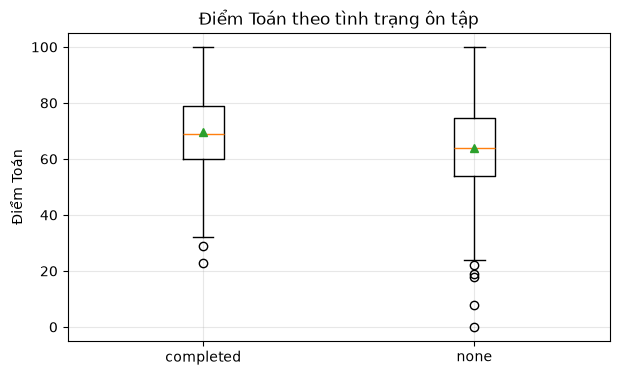


**Diễn giải (câu d).** Điểm Toán trung bình của nhóm `completed` (n₁ = 358) là 69.70 và của nhóm `none` (n₂ = 642) là 64.08,
chênh lệch mẫu 5.62 điểm. Với mức tin cậy 95%, hiệu μ₁ − μ₂ nằm trong **(3.72; 7.52) điểm**.
Khoảng không chứa 0 → ở mức 5%, có sự khác biệt về điểm Toán trung bình: nhóm đã hoàn thành khóa ôn tập cao hơn nhóm chưa ôn tập khoảng **3.72 đến 7.52 điểm**.

Vì n₁, n₂ đều lớn nên xấp xỉ chuẩn theo định lý giới hạn trung tâm là hợp lý; các khoảng đối chiếu (Satterthwaite, phương sai gộp) gần như trùng với khoảng z ở trên.

*Lưu ý:* đây là dữ liệu quan sát; chênh lệch có thể chịu ảnh hưởng của các yếu tố khác (điều kiện kinh tế, học vấn cha mẹ, …)
nên không khẳng định khóa ôn tập *gây ra* chênh lệch.


In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([x1, x2], showmeans=True)
ax.set_xticks([1, 2], ["completed", "none"])
ax.set_title("Điểm Toán theo tình trạng ôn tập"); ax.set_ylabel("Điểm Toán")
plt.show()

if lower_d > 0:
    kl = "cao hơn"; rng = f"{lower_d:.2f} đến {upper_d:.2f}"
elif upper_d < 0:
    kl = "thấp hơn"; rng = f"{-upper_d:.2f} đến {-lower_d:.2f}"
else:
    kl = None
if kl:
    ketluan = (f"Khoảng không chứa 0 → ở mức 5%, có sự khác biệt về điểm Toán trung bình: nhóm đã hoàn thành khóa ôn tập "
               f"{kl} nhóm chưa ôn tập khoảng **{rng} điểm**.")
else:
    ketluan = "Khoảng chứa 0 → chưa đủ bằng chứng ở mức 5% để kết luận hai nhóm có điểm Toán trung bình khác nhau."

display(Markdown(f'''
**Diễn giải (câu d).** Điểm Toán trung bình của nhóm `completed` (n₁ = {n1}) là {m1:.2f} và của nhóm `none` (n₂ = {n2}) là {m2_:.2f},
chênh lệch mẫu {diff:.2f} điểm. Với mức tin cậy 95%, hiệu μ₁ − μ₂ nằm trong **({lower_d:.2f}; {upper_d:.2f}) điểm**.
{ketluan}

Vì n₁, n₂ đều lớn nên xấp xỉ chuẩn theo định lý giới hạn trung tâm là hợp lý; các khoảng đối chiếu (Satterthwaite, phương sai gộp) gần như trùng với khoảng z ở trên.

*Lưu ý:* đây là dữ liệu quan sát; chênh lệch có thể chịu ảnh hưởng của các yếu tố khác (điều kiện kinh tế, học vấn cha mẹ, …)
nên không khẳng định khóa ôn tập *gây ra* chênh lệch.
'''))

---
# Tổng hợp kết quả

,Tham số,Phương pháp,Ước lượng điểm,Cận dưới,Cận trên,Độ rộng
0,a. Kỳ vọng μ (điểm Toán),z – mẫu lớn (CLT),66.0890,65.1492,67.0288,1.8796
1,b. Phương sai σ² (điểm Toán),χ² (cần tổng thể chuẩn),229.9190,211.0168,251.4933,40.4765
2,c. Tỷ lệ p (hoàn thành ôn tập),z – xấp xỉ chuẩn (CLT),0.3580,0.3283,0.3877,0.0594
3,d. Hiệu μ1−μ2 (completed − none),z – mẫu lớn (CLT),5.6176,3.7150,7.5203,3.8052


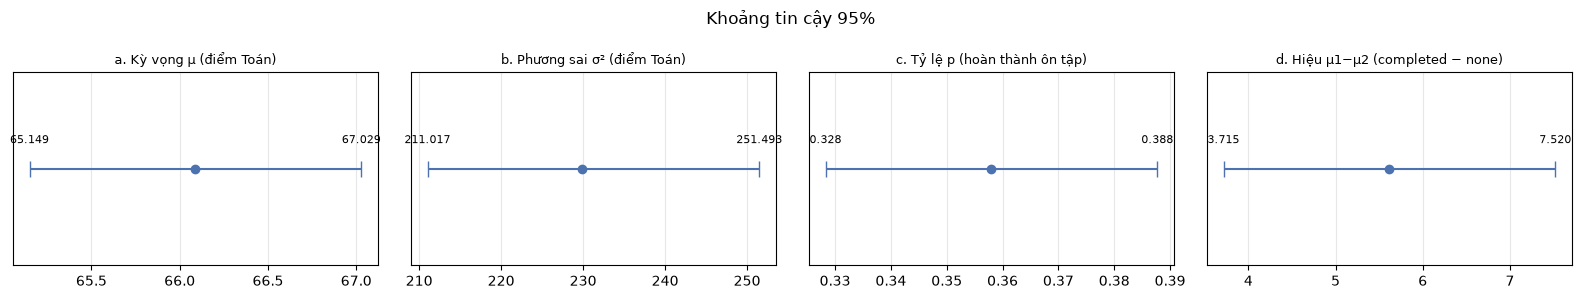

In [21]:
summary = pd.DataFrame([
    ["a. Kỳ vọng μ (điểm Toán)",            "z – mẫu lớn (CLT)",          xbar,  lower_a, upper_a],
    ["b. Phương sai σ² (điểm Toán)",        "χ² (cần tổng thể chuẩn)",    s2_a,  lower_b, upper_b],
    ["c. Tỷ lệ p (hoàn thành ôn tập)",      "z – xấp xỉ chuẩn (CLT)",     p_hat, wald_lo, wald_hi],
    ["d. Hiệu μ1−μ2 (completed − none)",    "z – mẫu lớn (CLT)",          diff,  lower_d, upper_d],
], columns=["Tham số", "Phương pháp", "Ước lượng điểm", "Cận dưới", "Cận trên"])
summary["Độ rộng"] = summary["Cận trên"] - summary["Cận dưới"]
display(summary)

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, (_, r) in zip(axes, summary.iterrows()):
    ax.errorbar(r["Ước lượng điểm"], 0, xerr=[[r["Ước lượng điểm"] - r["Cận dưới"]], [r["Cận trên"] - r["Ước lượng điểm"]]],
                fmt="o", capsize=6, color="#4C72B0")
    ax.set_yticks([]); ax.set_ylim(-0.3, 0.3)
    ax.set_title(r["Tham số"], fontsize=9)
    ax.text(r["Cận dưới"], 0.08, f"{r['Cận dưới']:.3f}", ha="center", fontsize=8)
    ax.text(r["Cận trên"], 0.08, f"{r['Cận trên']:.3f}", ha="center", fontsize=8)
fig.suptitle("Khoảng tin cậy 95%"); plt.tight_layout(); plt.show()

### Nhận xét chung và hạn chế
- **Cách hiểu đúng:** mức tin cậy 95% là tính chất của *phương pháp* dựng khoảng trong lặp lại lấy mẫu; một khoảng cụ thể hoặc chứa hoặc không chứa tham số thật. Khoảng tin cậy **không** chứa 95% giá trị cá nhân.
- **Định lý giới hạn trung tâm** cho phép dùng xấp xỉ chuẩn ở các câu a, c, d nhờ cỡ mẫu lớn, không cần giả định tổng thể chuẩn. Riêng câu b (phương sai) không được CLT hỗ trợ: khoảng $\chi^2$ phụ thuộc vào giả định chuẩn, nên là khoảng *có điều kiện*.
- **Tính đại diện:** bộ dữ liệu Kaggle không nêu rõ cơ chế lấy mẫu (có thể là dữ liệu mô phỏng) nên "tổng thể" chỉ là tổng thể mà mẫu này đại diện, khó suy rộng cho mọi học sinh.
- **Quan hệ nhân quả:** câu d chỉ phản ánh sự khác biệt giữa hai nhóm, không chứng minh khóa ôn tập làm tăng điểm.